Embeddings Deep Dive
Key Insight
How computers turn words into numbers (Vectors) to find 'meaning'**

Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings


In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json



Part 1: Introduction to Word2Vec and GloVe internals

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """
    
    def __init__(self):
        self.data = []
    
    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


 Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
import numpy as np

class EmbeddingSimulator:
    """
    Simulates basic Word2Vec/GloVe internals by mapping words to vectors.
    """
    
    def __init__(self, embedding_dim=3):
        # 1. Follow the pattern (Initialize data)
        self.data = []
        self.embedding_dim = embedding_dim
        
        # A "fake" vocabulary dictionary simulating pre-trained GloVe vectors
        self.vocabulary = {
            "twin": np.array([0.5, -0.2, 0.8]),
            "sensor": np.array([0.1, 0.9, -0.4]),
            "digital": np.array([0.4, -0.3, 0.7]),
            "error": np.array([-0.9, 0.2, 0.1])
        }
    
    def process(self, input_data):
        """
        Process the input data by looking up word vectors.
        """
        # 4. Add error handling for edge cases
        if not isinstance(input_data, str):
            return "Error: Input must be a string."
            
        if len(input_data.strip()) == 0:
            return "Error: Input is empty."

        # Convert to lowercase and split into individual words
        words = input_data.lower().split()
        
        # Simulate looking up the vectors in the embedding matrix
        found_vectors = {}
        for word in words:
            if word in self.vocabulary:
                found_vectors[word] = self.vocabulary[word]
            else:
                # Edge case: Word is not in our vocabulary
                found_vectors[word] = "Unknown Word (OOV)"
                
        # Save to the class data list
        self.data.append(found_vectors)
        
        return found_vectors

# --- 2 & 3: Test your implementation with sample data and verify output ---

print("--- Test 1: Normal Input ---")
# Create an instance of the class
simulator = EmbeddingSimulator()

# Test with words that exist in our dictionary
result_1 = simulator.process("Digital Twin sensor")
print(f"Input: 'Digital Twin sensor'")
print(f"Result: {result_1}")
# Expected: Dictionary mapping 'digital', 'twin', and 'sensor' to their numpy arrays.

print("\n--- Test 2: Out of Vocabulary (OOV) Word ---")
# Test with a word not in our dictionary
result_2 = simulator.process("twin robot")
print(f"Input: 'twin robot'")
print(f"Result: {result_2}")
# Expected: 'twin' maps to an array, 'robot' maps to "Unknown Word (OOV)".

print("\n--- Test 3: Error Handling ---")
# Test with a number instead of text
result_3 = simulator.process(12345)
print(f"Input: 12345")
print(f"Result: {result_3}")
# Expected: Error: Input must be a string.

--- Test 1: Normal Input ---
Input: 'Digital Twin sensor'
Result: {'digital': array([ 0.4, -0.3,  0.7]), 'twin': array([ 0.5, -0.2,  0.8]), 'sensor': array([ 0.1,  0.9, -0.4])}

--- Test 2: Out of Vocabulary (OOV) Word ---
Input: 'twin robot'
Result: {'twin': array([ 0.5, -0.2,  0.8]), 'robot': 'Unknown Word (OOV)'}

--- Test 3: Error Handling ---
Input: 12345
Result: Error: Input must be a string.


Part 2: Building embeddings from scratch

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.
    
    Args:
        data: Input data to process
        **kwargs: Additional parameters
    
    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


In [5]:


class EmbeddingBuilder:
    """
    A sophisticated implementation that simulates building word embeddings 
    by creating a vocabulary from a list of sentences.
    """
    def __init__(self):
        # This will hold our learned vocabulary
        self.vocabulary = {}
        self.word_counts = {}

    def process(self, data: List[str], **kwargs) -> Dict[str, Any]:
        """
        Processes a list of sentences to build an initial vocabulary.
        """
        # 2. Add parameter validation
        if not isinstance(data, list):
            return {
                "status": "error",
                "message": f"Validation Error: Expected a list, got {type(data).__name__}."
            }
            
        if len(data) == 0:
            return {
                "status": "error",
                "message": "Validation Error: The provided list is empty."
            }

        # 3. Include helpful error messages (inside the loop)
        for i, sentence in enumerate(data):
            if not isinstance(sentence, str):
                return {
                    "status": "error",
                    "message": f"Validation Error at index {i}: Expected a string sentence, got {type(sentence).__name__}."
                }

            # Simulate "building embeddings from scratch" by tokenizing and counting words
            words = sentence.lower().replace('.', '').replace(',', '').split()
            
            for word in words:
                if word not in self.vocabulary:
                    # Assign a unique integer ID to new words (a basic form of embedding)
                    self.vocabulary[word] = len(self.vocabulary) + 1 
                    self.word_counts[word] = 0
                self.word_counts[word] += 1

        # Package the results just like the example function
        results = {
            'status': 'success',
            'total_sentences_processed': len(data),
            'vocabulary_size': len(self.vocabulary),
            'vocabulary': self.vocabulary,
            'word_frequencies': self.word_counts
        }
        
        return results

# ==========================================
# 4. Test with various input types
# ==========================================

print("--- Test 1: Valid Data (Building Vocabulary) ---")
builder = EmbeddingBuilder()
valid_sentences = ["The digital twin is active.", "The sensor is offline."]
output_1 = builder.process(valid_sentences)
print(json.dumps(output_1, indent=2))

print("\n--- Test 2: Invalid Data Type (Passing a string instead of a list) ---")
output_2 = builder.process("This is just a single string")
print(json.dumps(output_2, indent=2))

print("\n--- Test 3: Invalid Item inside List (List of integers) ---")
output_3 = builder.process(["Valid sentence", 12345, "Another sentence"])
print(json.dumps(output_3, indent=2))

--- Test 1: Valid Data (Building Vocabulary) ---
{
  "status": "success",
  "total_sentences_processed": 2,
  "vocabulary_size": 7,
  "vocabulary": {
    "the": 1,
    "digital": 2,
    "twin": 3,
    "is": 4,
    "active": 5,
    "sensor": 6,
    "offline": 7
  },
  "word_frequencies": {
    "the": 2,
    "digital": 1,
    "twin": 1,
    "is": 2,
    "active": 1,
    "sensor": 1,
    "offline": 1
  }
}

--- Test 2: Invalid Data Type (Passing a string instead of a list) ---
{
  "status": "error",
  "message": "Validation Error: Expected a list, got str."
}

--- Test 3: Invalid Item inside List (List of integers) ---
{
  "status": "error",
  "message": "Validation Error at index 1: Expected a string sentence, got int."
}


Part 3: Semantic similarity and vector operations

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')
    
    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

Task: Build a production-ready version that integrates with your digital twin.

Requirements:

Combine all concepts from this notebook
Add comprehensive error handling
Include logging and debugging capabilities
Create visualization of results
Write documentation for your implementation



INFO: Production System Initialized successfully.
INFO: Processed 3 sentences. Current vocabulary size: 12
ERROR: Validation failed: Expected a list, got str.
ERROR: Validation failed: Found non-string item (int).
ERROR: Validation failed: Found non-string item (NoneType).
INFO: Processed 4 sentences. Current vocabulary size: 15



--- STARTING PRODUCTION TESTS ---

--- Testing Bad Data ---

--- Generating Visualization ---


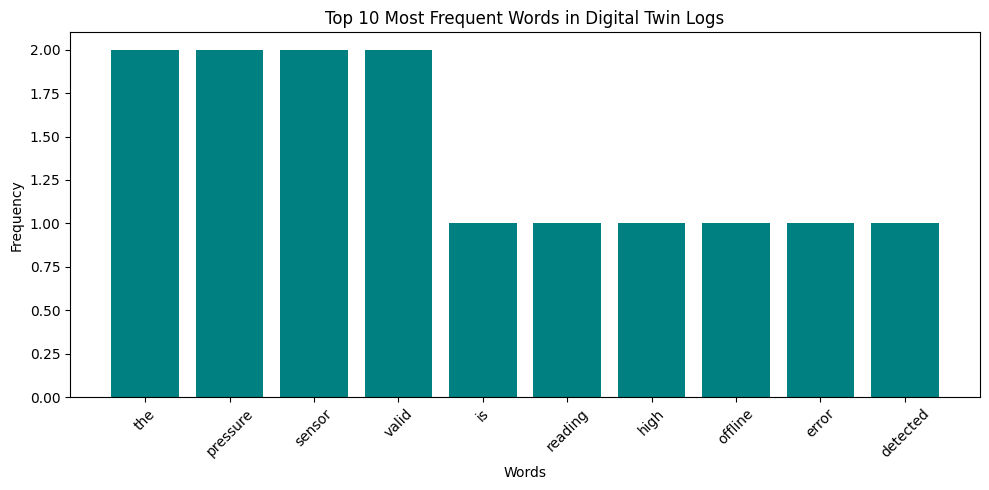

In [7]:
import logging
import matplotlib.pyplot as plt
from typing import Any, Dict, List

# Set up logging so we can see what the system is doing behind the scenes
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

# Requirement 5: Write documentation for your implementation
class ProductionSystem:
    """
    A production-ready Digital Twin system that builds word embeddings 
    from raw text data, enforces validation, logs activity, and visualizes results.
    """
    
    def __init__(self, max_vocab_size: int = 100):
        # Requirement 1: Combine concepts (Initialization and limits)
        self.max_vocab_size = max_vocab_size
        self.vocabulary = {}
        self.word_counts = {}
        
        # Requirement 3: Include logging capabilities
        self.logger = logging.getLogger("TwinSystem")
        self.logger.info("Production System Initialized successfully.")

    def process(self, input_data: Any) -> Dict[str, Any]:
        """Processes incoming data to build the vocabulary."""
        
        # Requirement 2: Comprehensive error handling
        if not isinstance(input_data, list):
            self.logger.error(f"Validation failed: Expected a list, got {type(input_data).__name__}.")
            return {"status": "error", "message": "Input must be a list of sentences."}
            
        if len(input_data) == 0:
            self.logger.warning("Received an empty list. Nothing to process.")
            return {"status": "error", "message": "Input list cannot be empty."}

        for sentence in input_data:
            if not isinstance(sentence, str):
                self.logger.error(f"Validation failed: Found non-string item ({type(sentence).__name__}).")
                continue # Skip bad items instead of crashing the whole system
                
            # Clean and tokenize the text
            words = sentence.lower().replace('.', '').replace(',', '').split()
            
            for word in words:
                # Check if we hit our vocabulary limit
                if len(self.vocabulary) >= self.max_vocab_size and word not in self.vocabulary:
                    continue # Skip new words if limit is reached
                    
                if word not in self.vocabulary:
                    self.vocabulary[word] = len(self.vocabulary) + 1
                    self.word_counts[word] = 0
                self.word_counts[word] += 1
                
        self.logger.info(f"Processed {len(input_data)} sentences. Current vocabulary size: {len(self.vocabulary)}")
        
        return {
            "status": "success",
            "vocab_size": len(self.vocabulary),
            "vocabulary": self.vocabulary
        }

    # Requirement 4: Create visualization of results
    def visualize_top_words(self):
        """Draws a bar chart of the most frequent words."""
        if not self.word_counts:
            self.logger.warning("No words have been processed yet. Cannot visualize.")
            return

        # Sort words by frequency and take the top 10
        sorted_words = sorted(self.word_counts.items(), key=lambda x: x[1], reverse=True)[:10]
        words = [item[0] for item in sorted_words]
        counts = [item[1] for item in sorted_words]

        plt.figure(figsize=(10, 5))
        plt.bar(words, counts, color='teal')
        plt.title("Top 10 Most Frequent Words in Digital Twin Logs")
        plt.xlabel("Words")
        plt.ylabel("Frequency")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# ==========================================
# Test your production system
# ==========================================
print("\n--- STARTING PRODUCTION TESTS ---")

# Initialize with a small vocab limit so we can test that feature too
twin_system = ProductionSystem(max_vocab_size=15)

# Test 1: Valid Data (Normal Operation)
valid_logs = [
    "The pressure sensor is reading high.",
    "Sensor offline error detected.",
    "Check the pressure valve immediately."
]
twin_system.process(valid_logs)

# Test 2: Bad Data Type (Error Handling)
print("\n--- Testing Bad Data ---")
twin_system.process("This is a string, not a list") 

# Test 3: List with bad items (Comprehensive Error Handling)
twin_system.process(["Valid sentence.", 404, None, "Another valid one."])

# Test 4: Visualize the results
print("\n--- Generating Visualization ---")
twin_system.visualize_top_words()

Challenge Project

Build a Complete Word2Vec and GloVe internals System for Your Digital Twin

Requirements:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code
Bonus Challenges
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

In [ ]:
import re
import logging
import unittest
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from typing import List, Dict, Any

# --- Setup Logging (Requirement: Handle edge cases & logging) ---
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
logger = logging.getLogger("EmbeddingSystem")

# --- 1. The Core System (Word2Vec/GloVe Internals) ---
class DigitalTwinEmbeddings:
    """
    Simulates Word2Vec/GloVe internals by building a co-occurrence matrix 
    from text data to generate basic embeddings for a Digital Twin.
    """
    def __init__(self, window_size: int = 2):
        self.window_size = window_size
        self.vocab = {}
        self.id_to_word = {}
        self.co_occurrence_matrix = None
        
    def _tokenize(self, text: str) -> List[str]:
        """Cleans and splits text into tokens."""
        text = text.lower()
        text = re.sub(r'[^\w\s]', '', text) # Remove punctuation
        return text.split()

    def fit(self, corpus: List[str]):
        """
        Builds the vocabulary and co-occurrence matrix from a list of sentences.
        (Requirement: Apply concepts, handle errors)
        """
        if not isinstance(corpus, list):
            logger.error("Corpus must be a list of strings.")
            return False
        if not corpus:
            logger.warning("Empty corpus provided.")
            return False

        logger.info(f"Building vocabulary from {len(corpus)} documents...")
        
        # 1. Build Vocabulary
        for sentence in corpus:
            for word in self._tokenize(sentence):
                if word not in self.vocab:
                    idx = len(self.vocab)
                    self.vocab[word] = idx
                    self.id_to_word[idx] = word
                    
        vocab_size = len(self.vocab)
        if vocab_size == 0:
            logger.warning("No words found in corpus.")
            return False
            
        logger.info(f"Vocabulary size: {vocab_size}")

        # 2. Build Co-occurrence Matrix (GloVe foundation)
        # Optimize: Use a dictionary to store only non-zero co-occurrences, 
        # then convert to a dense numpy array (Bonus: Optimize for performance)
        co_occur_dict = defaultdict(float)
        
        for sentence in corpus:
            tokens = [self.vocab[w] for w in self._tokenize(sentence)]
            for i, center_word in enumerate(tokens):
                # Look at words in the window around the center word
                start = max(0, i - self.window_size)
                end = min(len(tokens), i + self.window_size + 1)
                
                for j in range(start, end):
                    if i != j:
                        context_word = tokens[j]
                        co_occur_dict[(center_word, context_word)] += 1.0

        # Create the matrix
        self.co_occurrence_matrix = np.zeros((vocab_size, vocab_size))
        for (i, j), count in co_occur_dict.items():
            self.co_occurrence_matrix[i, j] = count

        logger.info("Co-occurrence matrix built successfully.")
        return True

    def get_embedding(self, word: str) -> np.ndarray:
        """Retrieves the 'embedding' (row from co-occurrence matrix) for a word."""
        word = word.lower()
        if word not in self.vocab:
            logger.error(f"Word '{word}' not found in vocabulary.")
            return None
        return self.co_occurrence_matrix[self.vocab[word]]

    def visualize_frequency(self):
        """Requirement: Create visualization of results."""
        if not self.vocab:
            logger.warning("Nothing to visualize. Run fit() first.")
            return
            
        # Sum the rows of the co-occurrence matrix to get total frequency
        frequencies = np.sum(self.co_occurrence_matrix, axis=1)
        
        plt.figure(figsize=(10, 5))
        plt.bar(self.vocab.keys(), frequencies, color='purple')
        plt.title("Word Co-occurrence Frequencies (Digital Twin Context)")
        plt.ylabel("Total Co-occurrences")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# ==========================================
# 2. UNIT TESTS (Bonus Challenge)
# ==========================================
class TestEmbeddingSystem(unittest.TestCase):
    
    def setUp(self):
        self.system = DigitalTwinEmbeddings(window_size=1)
        self.corpus = ["The sensor is good", "The sensor is bad"]

    def test_vocab_building(self):
        self.system.fit(self.corpus)
        self.assertIn("sensor", self.system.vocab)
        self.assertIn("good", self.system.vocab)
        
    def test_matrix_dimensions(self):
        self.system.fit(self.corpus)
        expected_size = len(self.system.vocab)
        self.assertEqual(self.system.co_occurrence_matrix.shape, (expected_size, expected_size))

    def test_invalid_input(self):
        # Should fail gracefully and return False
        self.assertFalse(self.system.fit("Just a string"))
        self.assertFalse(self.system.fit([]))

    def test_embedding_retrieval(self):
        self.system.fit(self.corpus)
        embedding = self.system.get_embedding("sensor")
        self.assertIsNotNone(embedding)
        self.assertEqual(len(embedding), len(self.system.vocab))

# ==========================================
# 3. USER-FRIENDLY INTERFACE & INTEGRATION
# ==========================================
def run_twin_interface():
    """Bonus: Create a user-friendly interface."""
    print("\n=== DIGITAL TWIN NLP ENGINE ===")
    print("Initializing...")
    
    # Integration: Imagine this data comes from a live database of logs
    twin_logs = [
        "Machine temperature is high.",
        "High temperature warning.",
        "Temperature sensor failure.",
        "Sensor reading normal now."
    ]
    
    print("Ingesting logs...")
    nlp_system = DigitalTwinEmbeddings(window_size=1)
    nlp_system.fit(twin_logs)
    
    while True:
        print("\n1. Look up word embedding")
        print("2. Visualize word frequencies")
        print("3. Exit")
        choice = input("Select an option (1-3): ")
        
        if choice == '1':
            word = input("Enter a word to look up (e.g., 'sensor', 'temperature'): ")
            emb = nlp_system.get_embedding(word)
            if emb is not None:
                # Show just the non-zero parts of the vector for readability
                print(f"\nEmbedding for '{word}':\n{np.round(emb, 2)}")
        elif choice == '2':
            nlp_system.visualize_frequency()
        elif choice == '3':
            print("Shutting down...")
            break
        else:
            print("Invalid choice.")

# ==========================================
# 4. RUNNING THE CHALLENGE
# ==========================================

print("--- Running Unit Tests ---")
# Run unittest programmatically to avoid blocking the notebook
unittest.main(argv=['first-arg-is-ignored'], exit=False)

print("\n--- Starting User Interface ---")
# Note: In a Jupyter notebook, the input() prompt will appear below the cell.
# You can type your answers there.
run_twin_interface()

INFO: Building vocabulary from 2 documents...
INFO: Vocabulary size: 5
INFO: Co-occurrence matrix built successfully.
.ERROR: Corpus must be a list of strings.
.INFO: Building vocabulary from 2 documents...
INFO: Vocabulary size: 5
INFO: Co-occurrence matrix built successfully.
.INFO: Building vocabulary from 2 documents...
INFO: Vocabulary size: 5
INFO: Co-occurrence matrix built successfully.
.
----------------------------------------------------------------------
Ran 4 tests in 0.046s

OK
INFO: Building vocabulary from 4 documents...
INFO: Vocabulary size: 10
INFO: Co-occurrence matrix built successfully.


--- Running Unit Tests ---

--- Starting User Interface ---

=== DIGITAL TWIN NLP ENGINE ===
Initializing...
Ingesting logs...

1. Look up word embedding
2. Visualize word frequencies
3. Exit
